# A04 — Processamento e integração: o original e duas correções

## O que este notebook faz

Aplica ao ressequenciamento o processamento de `src/scripts/processing.ipynb`
— concatenação, genes variáveis, PCA, Harmony, vizinhança, UMAP e Leiden — em
três variantes sobre **as mesmas células**, mudando uma coisa por vez:

| variante | universo de genes | matriz que entra na PCA | para que serve |
| --- | --- | --- | --- |
| **V1 fiel** | interseção entre bibliotecas | contagens cruas | é o original, linha por linha |
| **V2** | interseção | lognorm escalonada | isola o efeito da PCA |
| **V3** | união + filtro global | lognorm escalonada | isola o efeito do universo de genes |

Em todas: 2.000 genes variáveis (`seurat_v3`, por biblioteca), 50 componentes,
Harmony por biblioteca, vizinhança nas 15 primeiras dimensões, Leiden 0,5.

A V1 repete também o que a auditoria anterior apontou como defeito: a PCA do
original roda sobre contagens cruas, porque `normalize_pearson_residuals(...,
layer="counts")` grava na layer e deixa `X` intacto. Repetir é o que permite
dizer se o defeito reaparece nos dados novos.

A avaliação dos clusters (composição, mistura de bibliotecas, estabilidade,
concordância com a corrida antiga) fica em A05. Aqui não há anotação de
subtipos.

## Entradas

Os 14 objetos pós-QC de A01 (`dataReseq/A01_preprocessamento/new/`). Para o
teste de fidelidade, os objetos antigos em `data/new/` e o resultado gravado
pelo notebook original, `data/adata_harmony.h5ad` — ambos só lidos.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import time
import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

from functions import config, fmt as F, io, pipeline as pl, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
sc.settings.verbosity = 0

NB = "A04_processamento_integracao"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK
VARS = pl.VARIANTS
VCOL = plotting.VARIANT_COLORS
VLAB = plotting.VARIANT_LABEL


def comp_corr(A, B, n=10):
    """|r| de Pearson, componente a componente (o sinal de uma componente é arbitrário)."""
    return np.array([abs(np.corrcoef(A[:, k], B[:, k])[0, 1]) for k in range(n)])

## 1. A réplica é fiel? Teste nos dados antigos

Antes de aplicar o processamento aos dados novos, a V1 roda sobre os objetos
da corrida antiga e é comparada com o que o notebook original gravou. Se a
réplica estiver certa, os dois resultados coincidem.

In [2]:
t0 = time.time()
antigos = pl.load_old_postqc()
old_inner = pl.build_universe(antigos, "inner")
old_union = pl.build_universe(antigos, "union")
del antigos
hvg_old = pl.select_hvg(old_inner)
rep = pl.run_variant(old_inner, "V1", hvg_old)

ref = ad.read_h5ad(config.OLD_HARMONY, backed="r")
ref_obs = ref.obs.copy()
ref_var = ref.var.copy()
ref_pca = np.asarray(ref.obsm["X_pca"])
ref_harm = np.asarray(ref.obsm["X_emb_harmony"])
ref_vr = float(np.asarray(ref.uns["pca"]["variance_ratio"]).sum())
ref.file.close()

mesma_ordem = bool((rep.obs["barcode"].to_numpy() == ref_obs.index.str[:18].to_numpy()).all()
                   and (rep.obs["library_id"].astype(str).to_numpy()
                        == ref_obs["library_id"].astype(str).to_numpy()).all())
hvg_comum = len(set(rep.var["gene_ids"]) & set(ref_var["gene_ids"]))
r_pca = comp_corr(rep.obsm["X_pca"], ref_pca)
r_harm = comp_corr(rep.obsm["X_emb_harmony"], ref_harm)
conc = pl.clustering_agreement(rep.obs["leiden"], ref_obs["leiden"])
vr_rep = float(rep.uns["pca"]["variance_ratio"].sum())

fidel = pd.DataFrame([
    ["células × genes após a concatenação", f"{F.n(config.OLD_INTEGRATED_SHAPE[0])} × {F.n(config.OLD_INTEGRATED_SHAPE[1])}",
     f"{F.n(old_inner.n_obs)} × {F.n(old_inner.n_vars)}", old_inner.shape == config.OLD_INTEGRATED_SHAPE],
    ["células na mesma ordem e na mesma biblioteca", "—", "sim" if mesma_ordem else "não", mesma_ordem],
    ["genes variáveis em comum", F.n(config.N_HVG), F.n(hvg_comum), hvg_comum == config.N_HVG],
    ["variância nas 50 componentes", F.pct(ref_vr), F.pct(vr_rep), abs(ref_vr - vr_rep) < 1e-3],
    ["menor |r| nas 10 primeiras componentes da PCA", "1", F.f(r_pca.min(), 4), r_pca.min() > 0.999],
    ["menor |r| nas 10 primeiras dimensões do Harmony", "1", F.f(r_harm.min(), 4), r_harm.min() > 0.999],
    ["clusters do Leiden 0,5", F.n(ref_obs["leiden"].nunique()), F.n(rep.obs["leiden"].nunique()),
     ref_obs["leiden"].nunique() == rep.obs["leiden"].nunique()],
    ["índice de Rand ajustado entre os dois agrupamentos", "1", F.f(conc["ARI"], 4), conc["ARI"] > 0.99],
], columns=["verificação", "original gravado", "réplica (V1)", "confere"]).set_index("verificação")
io.save_table(fidel, NB, "fidelidade_da_replica",
              description="V1 sobre os dados antigos × adata_harmony.h5ad gravado pelo notebook original")
assert fidel["confere"].all(), "a réplica V1 não reproduz o processamento original"

# assinatura de profundidade da corrida antiga, para comparar adiante
rho_antiga = {"PCA": pl.depth_correlation(ref_pca, ref_obs["total_counts"].to_numpy()),
              "Harmony": pl.depth_correlation(ref_harm, ref_obs["total_counts"].to_numpy())}
print(f"réplica conferida em {time.time() - t0:.0f} s")
del ref_pca, ref_harm
fidel

  V1: 34,931 células × 17,761 genes no universo; PCA sobre contagens cruas; variância em 50 PCs 0.982; 14 clusters; Harmony: Converged after 7 iterations


réplica conferida em 104 s


,original gravado,réplica (V1),confere
verificação,,,
células × genes após a concatenação,34.931 × 17.761,34.931 × 17.761,True
células na mesma ordem e na mesma biblioteca,—,sim,True
genes variáveis em comum,2.000,2.000,True
variância nas 50 componentes,"98,2%","98,2%",True
menor |r| nas 10 primeiras componentes da PCA,1,"1,0000",True
menor |r| nas 10 primeiras dimensões do Harmony,1,"1,0000",True
"clusters do Leiden 0,5",14,14,True
índice de Rand ajustado entre os dois agrupamentos,1,"1,0000",True


**Leitura.** A réplica reproduz o resultado gravado: mesmas células, os
mesmos 2.000 genes variáveis, as mesmas componentes e o mesmo agrupamento. O
que a V1 mostrar nos dados novos é, portanto, o que o notebook original
produziria.

In [3]:
log.add("INFO", "réplica do processing.ipynb (variante V1)",
        "[VERIFICAÇÃO] a V1 reproduz o resultado gravado pelo notebook original",
        evidence=f"{F.n(hvg_comum)} de {F.n(config.N_HVG)} genes variáveis em comum; menor |r| das 10 primeiras "
                 f"dimensões do Harmony {F.f(r_harm.min(), 4)}; índice de Rand ajustado {F.f(conc['ARI'], 4)}",
        impact="o comportamento da V1 nos dados novos pode ser atribuído ao processamento original, não à réplica",
        recommendation="nenhuma")

### As outras duas variantes na corrida antiga

Para que A05 compare corrida antiga e ressequenciamento processados pelo
mesmo código, a V2 e a V3 também rodam sobre os dados antigos. Só os rótulos
de cluster e o número de UMIs por célula são guardados.

In [4]:
t0 = time.time()
rep2 = pl.run_variant(old_inner, "V2", hvg_old)
rep3 = pl.run_variant(old_union, "V3")
assert (rep2.obs_names == rep.obs_names).all() and (rep3.obs_names == rep.obs_names).all()
antiga = pd.DataFrame({
    "cell_key": old_union.obs["cell_key"].to_numpy(),
    "library_id": old_union.obs["library_id"].astype(str).to_numpy(),
    "barcode": old_union.obs["barcode"].to_numpy(),
    "total_counts": old_union.obs["total_counts"].to_numpy(),
    "leiden_V1": rep.obs["leiden"].astype(str).to_numpy(),
    "leiden_V2": rep2.obs["leiden"].astype(str).to_numpy(),
    "leiden_V3": rep3.obs["leiden"].astype(str).to_numpy(),
})
assert antiga["cell_key"].is_unique
io.save_data(antiga, NB, "antiga_variantes",
             description="Corrida antiga processada pelas três variantes: rótulos de cluster e UMIs por célula")
antiga_resumo = pd.DataFrame({
    "universo (genes)": {"V1": old_inner.n_vars, "V2": old_inner.n_vars, "V3": old_union.n_vars},
    "variância nas 50 componentes": {v: float(a.uns["pca"]["variance_ratio"].sum()) for v, a in zip(pl.VARIANTS, (rep, rep2, rep3))},
    "clusters (Leiden 0,5)": {v: int(a.obs["leiden"].nunique()) for v, a in zip(pl.VARIANTS, (rep, rep2, rep3))},
})
io.save_table(antiga_resumo, NB, "variantes_na_corrida_antiga", description="As três variantes aplicadas à corrida antiga")
print(f"{F.n(len(antiga))} células da corrida antiga, três variantes, em {time.time() - t0:.0f} s")
del old_inner, old_union, rep, rep2, rep3
antiga_resumo

  V2: 34,931 células × 17,761 genes no universo; PCA sobre lognorm escalonada; variância em 50 PCs 0.164; 12 clusters; Harmony: Converged after 3 iterations


  V3: 34,931 células × 30,680 genes no universo; PCA sobre lognorm escalonada; variância em 50 PCs 0.176; 11 clusters; Harmony: Converged after 3 iterations
34.931 células da corrida antiga, três variantes, em 162 s


,universo (genes),variância nas 50 componentes,"clusters (Leiden 0,5)"
V1,17761,0.981594,14
V2,17761,0.164411,12
V3,30680,0.175828,11


## 2. Universos de genes e genes variáveis

A interseção mantém só os genes detectados nas 14 bibliotecas. A união mantém
todos e aplica um único filtro no conjunto (gene presente em pelo menos
3 células). Como as 14 bibliotecas usam a mesma referência, um gene ausente
de uma biblioteca é contagem zero de verdade: preencher com 0 é exato.

In [5]:
adatas = pl.load_postqc()
inner = pl.build_universe(adatas, "inner")
union = pl.build_universe(adatas, "union")
del adatas
assert (inner.obs_names == union.obs_names).all()
N_CELLS = union.n_obs

na_inter = union.var_names.isin(inner.var_names)
assert int(na_inter.sum()) == inner.n_vars, "o filtro global removeu genes da interseção"
frac_umis_extra = float(union.layers["counts"][:, ~na_inter].sum() / union.layers["counts"].sum())

hvg = {"inner": pl.select_hvg(inner), "union": pl.select_hvg(union)}
assert pl.hvg_matches_scanpy(inner, hvg["inner"]), "seleção de HVG difere do scanpy na interseção"
hv_set = {k: set(t.index[t["highly_variable"]]) for k, t in hvg.items()}
spans_fora = {b: s for b, s in hvg["union"].attrs["spans"].items() if s != 0.3}

pos = pd.Series(np.asarray((union.layers["counts"] > 0).sum(axis=0)).ravel(), index=union.var_names)
cito = pd.DataFrame({
    "células positivas": [int(pos.get(g, 0)) for g in config.CYTOKINES],
    "na interseção": [g in inner.var_names for g in config.CYTOKINES],
    "na união": [g in union.var_names for g in config.CYTOKINES],
    "gene variável na interseção": [g in hv_set["inner"] for g in config.CYTOKINES],
    "gene variável na união": [g in hv_set["union"] for g in config.CYTOKINES],
}, index=pd.Index(config.CYTOKINES, name="citocina"))
io.save_table(cito, NB, "citocinas_por_universo", description="Citocinas em cada universo de genes e entre os genes variáveis")

universos = pd.DataFrame({
    "genes": [inner.n_vars, union.n_vars],
    "citocinas presentes (de 16)": [int(cito["na interseção"].sum()), int(cito["na união"].sum())],
    "citocinas entre os genes variáveis": [int(cito["gene variável na interseção"].sum()),
                                           int(cito["gene variável na união"].sum())],
}, index=["interseção (V1, V2)", f"união + min_cells={config.GLOBAL_MIN_CELLS} (V3)"])
io.save_table(universos, NB, "universos_de_genes", description="Tamanho de cada universo de genes")
print(f"{F.n(N_CELLS)} células de {len(LIBS)} bibliotecas ({config.N_PATIENTS} pacientes)")
print(f"genes só na união: {F.n(union.n_vars - inner.n_vars)}, somando {F.pct(frac_umis_extra, 2)} dos UMIs")
print(f"genes variáveis em comum entre os dois universos: {F.n(len(hv_set['inner'] & hv_set['union']))} de {F.n(config.N_HVG)}")
print(f"seleção na interseção idêntica à do scanpy; na união o loess precisou de span maior em: {spans_fora or 'nenhuma biblioteca'}")
print("citocinas fora da interseção:", ", ".join(cito.index[~cito["na interseção"]]))
universos

35.064 células de 14 bibliotecas (7 pacientes)
genes só na união: 12.904, somando 0,28% dos UMIs
genes variáveis em comum entre os dois universos: 1.478 de 2.000
seleção na interseção idêntica à do scanpy; na união o loess precisou de span maior em: {'CTH94_ML': 0.4, 'HNP44_NS': 0.4, 'PB20_NS': 0.4}
citocinas fora da interseção: IL2, IL4, IL9, IL10, IL13, IL17A, IL17F, IL21, IL22, CSF2, IL31, IL3


,genes,citocinas presentes (de 16),citocinas entre os genes variáveis
"interseção (V1, V2)",18852,4,3
união + min_cells=3 (V3),31756,15,10


## 3. As três variantes

In [6]:
entrada = {"V1": (inner, hvg["inner"]), "V2": (inner, hvg["inner"]), "V3": (union, hvg["union"])}
res, tempo = {}, {}
for v in VARS:
    t0 = time.time()
    res[v] = pl.run_variant(entrada[v][0], v, entrada[v][1])
    tempo[v] = time.time() - t0
for v in VARS:
    assert (res[v].obs_names == union.obs_names).all()
    assert np.isfinite(res[v].obsm["X_emb_harmony"]).all() and np.isfinite(res[v].obsm["X_umap"]).all()

umis = union.obs["total_counts"].to_numpy()
tam = {v: res[v].obs["leiden"].astype(str).value_counts() for v in VARS}
variantes = pd.DataFrame({
    "universo (genes)": {v: entrada[v][0].n_vars for v in VARS},
    "genes variáveis em comum com a V1": {v: len(set(res[v].var_names) & set(res["V1"].var_names)) for v in VARS},
    "matriz na PCA": {v: res[v].uns["reseq_variant"]["pca_input"] for v in VARS},
    "variância nas 50 componentes": {v: float(res[v].uns["pca"]["variance_ratio"].sum()) for v in VARS},
    "variância na 1ª componente": {v: float(res[v].uns["pca"]["variance_ratio"][0]) for v in VARS},
    "clusters (Leiden 0,5)": {v: int(tam[v].size) for v in VARS},
    "maior cluster (células)": {v: int(tam[v].max()) for v in VARS},
    "menor cluster (células)": {v: int(tam[v].min()) for v in VARS},
    "clusters com menos de 50 células": {v: int((tam[v] < 50).sum()) for v in VARS},
    "Harmony": {v: res[v].uns["reseq_variant"]["harmony"] for v in VARS},
    "tempo (s)": {v: round(tempo[v]) for v in VARS},
})
variantes.index = [VLAB[v] for v in VARS]
io.save_table(variantes, NB, "variantes", description="As três variantes do processamento: universo, PCA e agrupamento")
variantes.T

  V1: 35,064 células × 18,852 genes no universo; PCA sobre contagens cruas; variância em 50 PCs 0.981; 14 clusters; Harmony: Converged after 9 iterations


  V2: 35,064 células × 18,852 genes no universo; PCA sobre lognorm escalonada; variância em 50 PCs 0.169; 10 clusters; Harmony: Converged after 3 iterations


  V3: 35,064 células × 31,756 genes no universo; PCA sobre lognorm escalonada; variância em 50 PCs 0.180; 13 clusters; Harmony: Converged after 4 iterations


,V1 fiel,V2 PCA corrigida,V3 + universo completo
universo (genes),18852,18852,31756
genes variáveis em comum com a V1,2000,2000,1478
matriz na PCA,contagens cruas,lognorm escalonada,lognorm escalonada
variância nas 50 componentes,0.980683,0.168853,0.179516
variância na 1ª componente,0.566857,0.037759,0.035083
"clusters (Leiden 0,5)",14,10,13
maior cluster (células),5843,8822,8067
menor cluster (células),43,122,93
clusters com menos de 50 células,1,0,0
Harmony,Converged after 9 iterations,Converged after 3 iterations,Converged after 4 iterations


## 4. O que a PCA enxerga em cada variante

A PCA procura as direções de maior variância. Em contagens cruas a variância
de um gene cresce com a sua expressão, de modo que poucos genes muito
expressos dominam a soma — e o que mais varia neles entre células é quanto RNA
cada célula teve capturado. Três medidas mostram isso: quanto da variância
total da matriz vem dos 10 genes de maior variância, quais genes carregam a
primeira componente, e quanto as primeiras dimensões acompanham o número de
UMIs da célula.

In [7]:
linhas, cargas = [], []
for v in VARS:
    a = res[v]
    X = a.X
    if hasattr(X, "toarray"):
        var_g = np.asarray(X.power(2).mean(axis=0)).ravel() - np.asarray(X.mean(axis=0)).ravel() ** 2
    else:
        var_g = X.var(axis=0)
    var_g = pd.Series(var_g, index=a.var_names).sort_values(ascending=False)
    L = pd.DataFrame(a.varm["PCs"], index=a.var_names)
    top1 = (L[0] ** 2).sort_values(ascending=False)
    linhas.append({
        "variante": VLAB[v],
        "variância da matriz nos 10 genes de maior variância": float(var_g.iloc[:10].sum() / var_g.sum()),
        "os 5 de maior variância": ", ".join(var_g.index[:5]),
        "carga² da 1ª componente nos 10 genes principais": float(top1.iloc[:10].sum()),
        "genes que carregam a 1ª componente": ", ".join(top1.index[:6]),
    })
    for k in range(5):
        sq = (L[k] ** 2).sort_values(ascending=False)
        for g, val in sq.iloc[:10].items():
            cargas.append({"variante": v, "componente": k + 1, "gene": g, "carga": float(L.loc[g, k]),
                           "carga²": float(val)})
pca_diag = pd.DataFrame(linhas).set_index("variante")
io.save_table(pca_diag, NB, "pca_concentracao", description="Concentração da variância e da 1ª componente em poucos genes")
io.save_table(pd.DataFrame(cargas), NB, "pca_cargas_principais", index=False,
              description="Os 10 genes de maior carga nas 5 primeiras componentes de cada variante")

rho = {}
for v in VARS:
    rho[(v, "PCA")] = pl.depth_correlation(res[v].obsm["X_pca"], umis)
    rho[(v, "Harmony")] = pl.depth_correlation(res[v].obsm["X_emb_harmony"], umis)
rho_tab = pd.DataFrame({**{(VLAB[v], e): val for (v, e), val in rho.items()},
                        **{("corrida antiga (original)", e): val for e, val in rho_antiga.items()}},
                       index=[f"dim {k}" for k in range(1, 6)]).T
rho_tab.index = rho_tab.index.set_names(["variante", "espaço"])
io.save_table(rho_tab, NB, "profundidade_por_dimensao",
              description="|ρ de Spearman| entre as 5 primeiras dimensões e o nº de UMIs por célula")
display(pca_diag.T)
rho_tab.round(2)

variante,V1 fiel,V2 PCA corrigida,V3 + universo completo
variância da matriz nos 10 genes de maior variância,0.917042,0.006024,0.00686
os 5 de maior variância,"MALAT1, IGKC, IGLC2, FTH1, IGHA1","RPL28, FTL, MT-CYB, SH3BGRL3, MBNL1","MT-CO3, RPS5, MT-ATP6, ACTB, LRRN3"
carga² da 1ª componente nos 10 genes principais,0.97522,0.074394,0.090532
genes que carregam a 1ª componente,"MALAT1, FTH1, MT-ATP6, MT-ND3, MT-CO3, ANK3","TALAM1, RPL28, ZBTB20, LINC-PINT, PDE3B, MBNL1","TALAM1, RPL28, ZBTB20, LINC-PINT, PDE3B, MBNL1"


dim 1  dim 2  dim 3  dim 4  dim 5
variante                  espaço                                    
V1 fiel                   PCA       0.82   0.77   0.54   0.08   0.21
                          Harmony   0.74   0.70   0.43   0.02   0.20
V2 PCA corrigida          PCA       0.63   0.30   0.20   0.12   0.06
                          Harmony   0.58   0.24   0.20   0.16   0.01
V3 + universo completo    PCA       0.63   0.31   0.22   0.12   0.05
                          Harmony   0.57   0.25   0.21   0.16   0.03
corrida antiga (original) PCA       0.78   0.73   0.62   0.08   0.30
                          Harmony   0.70   0.66   0.50   0.01   0.30

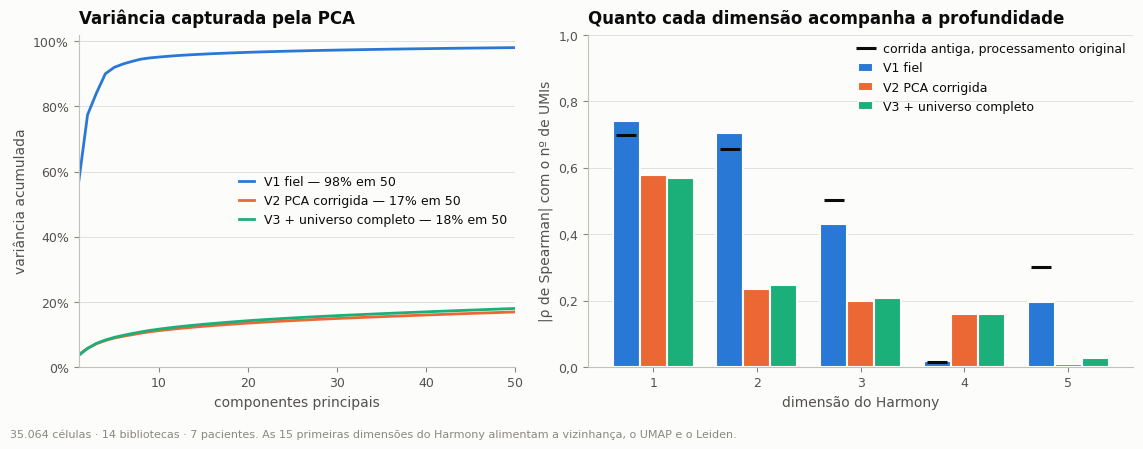

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1, 1.25]})
xs = np.arange(1, config.N_PCS + 1)
for v in VARS:
    cum = np.cumsum(res[v].uns["pca"]["variance_ratio"])
    a1.plot(xs, cum, color=VCOL[v], lw=2, label=f"{VLAB[v]} — {F.pct(cum[-1], 0)} em 50")
a1.set_ylim(0, 1.02)
a1.set_xlim(1, config.N_PCS)
plotting.percent(a1, "y")
a1.set_xlabel("componentes principais")
a1.set_ylabel("variância acumulada")
a1.set_title("Variância capturada pela PCA")
a1.legend(loc="center right")

w = 0.26
dims = np.arange(1, 6)
for i, v in enumerate(VARS):
    a2.bar(dims + (i - 1) * w, rho[(v, "Harmony")], width=w, color=VCOL[v],
           edgecolor=INK["surface"], linewidth=1.5, label=VLAB[v], zorder=3)
a2.plot(dims - w, rho_antiga["Harmony"], ls="", marker="_", ms=15, mew=2.2, color=INK["primary"], zorder=4,
        label="corrida antiga, processamento original")
a2.set_xticks(dims)
a2.set_ylim(0, 1)
plotting.decimals(a2, "y", 1)
a2.set_xlabel("dimensão do Harmony")
a2.set_ylabel("|ρ de Spearman| com o nº de UMIs")
a2.set_title("Quanto cada dimensão acompanha a profundidade")
a2.grid(axis="x", visible=False)
a2.legend(loc="upper right", ncol=1)
plotting.note(fig, f"{F.n(N_CELLS)} células · {plotting.N_DESIGN}. As 15 primeiras dimensões do Harmony alimentam a "
                   "vizinhança, o UMAP e o Leiden.")
fig.tight_layout()
dados_fig = pd.concat([
    pd.DataFrame({v: np.cumsum(res[v].uns["pca"]["variance_ratio"]) for v in VARS}, index=xs)
      .rename_axis("componente").reset_index().assign(painel="variância acumulada"),
    pd.DataFrame({**{v: rho[(v, "Harmony")] for v in VARS}, "corrida antiga": rho_antiga["Harmony"]}, index=dims)
      .rename_axis("componente").reset_index().assign(painel="|rho| com UMIs (Harmony)")])
plotting.savefig(fig, NB, "pca_por_variante", description="Variância capturada pela PCA e correlação das dimensões com a profundidade",
                 data=dados_fig, data_index=False)
plt.show()

In [9]:
v1, v2, v3 = (pca_diag.loc[VLAB[v]] for v in VARS)
r1, r2, r3 = (rho[(v, "Harmony")] for v in VARS)
print(f"V1: {F.pct(variantes.loc[VLAB['V1'], 'variância nas 50 componentes'])} da variância em 50 componentes, "
      f"{F.pct(variantes.loc[VLAB['V1'], 'variância na 1ª componente'])} só na primeira; "
      f"{F.pct(v1.iloc[0])} da variância da matriz vem de 10 genes ({v1.iloc[1]}).")
print(f"V2: {F.pct(variantes.loc[VLAB['V2'], 'variância nas 50 componentes'])} em 50 componentes; "
      f"10 genes somam {F.pct(v2.iloc[0], 2)} da variância.")
print(f"|ρ| das 3 primeiras dimensões do Harmony com os UMIs — V1: {', '.join(F.f(x, 2) for x in r1[:3])}; "
      f"V2: {', '.join(F.f(x, 2) for x in r2[:3])}; V3: {', '.join(F.f(x, 2) for x in r3[:3])}; "
      f"corrida antiga: {', '.join(F.f(x, 2) for x in rho_antiga['Harmony'][:3])}")

V1: 98,1% da variância em 50 componentes, 56,7% só na primeira; 91,7% da variância da matriz vem de 10 genes (MALAT1, IGKC, IGLC2, FTH1, IGHA1).
V2: 16,9% em 50 componentes; 10 genes somam 0,60% da variância.
|ρ| das 3 primeiras dimensões do Harmony com os UMIs — V1: 0,74, 0,70, 0,43; V2: 0,58, 0,24, 0,20; V3: 0,57, 0,25, 0,21; corrida antiga: 0,70, 0,66, 0,50


**Leitura.** O defeito se repete por inteiro nos dados novos. Na V1, 50
componentes capturam 98% da variância e a primeira, sozinha, 57%; 92% da
variância da matriz que entra na PCA está em 10 genes — MALAT1, FTH1 e, entre
os cinco primeiros, três de imunoglobulina (IGKC, IGLC2, IGHA1), que vêm de
poucas células B e plasmócitos com contagens altíssimas. Uma PCA assim
descreve a escala das contagens, não programas de expressão. As três
primeiras dimensões do Harmony acompanham o número de UMIs com |ρ| de 0,74,
0,70 e 0,43, praticamente o mesmo da corrida antiga (0,70, 0,66, 0,50): mais
profundidade não muda nada, porque a causa está no código.

Com a PCA corrigida (V2, V3) a variância se espalha — 17–18% em 50
componentes, nenhum gene com mais de 1% — e só a primeira dimensão continua
correlacionada com os UMIs (|ρ| 0,57–0,58).

Uma ressalva sobre a segunda medida: mesmo num processamento correto a
primeira dimensão pode acompanhar o número de UMIs, porque células ativadas
têm de fato mais RNA. O sinal do defeito é o conjunto — a concentração da
variância e várias dimensões correlacionadas ao mesmo tempo —, e a avaliação
por cluster, dentro de cada biblioteca, está em A05.

In [10]:
sev = "CRITICAL" if variantes.loc[VLAB["V1"], "variância nas 50 componentes"] > 0.9 else "MINOR"
log.add(sev, "processing.ipynb célula 054 → variante V1",
        "aplicado aos dados novos, o processamento original volta a calcular a PCA sobre contagens cruas",
        evidence=f"V1: {F.pct(variantes.loc[VLAB['V1'], 'variância nas 50 componentes'])} da variância em 50 componentes "
                 f"(V2: {F.pct(variantes.loc[VLAB['V2'], 'variância nas 50 componentes'])}); "
                 f"{F.pct(v1.iloc[0])} da variância da matriz em 10 genes ({v1.iloc[1]}); |ρ| das 3 primeiras dimensões "
                 f"do Harmony com os UMIs {', '.join(F.f(x, 2) for x in r1[:3])} "
                 f"(corrida antiga: {', '.join(F.f(x, 2) for x in rho_antiga['Harmony'][:3])})",
        impact="o grafo, o UMAP e os clusters da V1 são construídos num espaço dominado pela escala das contagens; "
               "o ressequenciamento não altera isso, porque a causa está no código",
        recommendation="usar a PCA sobre a lognorm escalonada dos genes variáveis (V2/V3)")

## 5. Quanto os agrupamentos concordam entre variantes

V1 × V2 mede o efeito de corrigir a PCA; V2 × V3 mede o efeito de trocar o
universo de genes. O índice de Rand ajustado (ARI) vale 1 para partições
idênticas e 0 para a concordância esperada ao acaso; a informação mútua
normalizada (NMI) é menos sensível ao tamanho dos clusters. Para ter uma
referência do que é "igual", a última linha compara duas execuções do Leiden
sobre o mesmo grafo da V3, mudando só a semente.

In [11]:
pares = [("V1", "V2", "efeito da PCA"), ("V2", "V3", "efeito do universo de genes"), ("V1", "V3", "os dois efeitos")]
linhas = []
for a, b, papel in pares:
    c = pl.clustering_agreement(res[a].obs["leiden"], res[b].obs["leiden"])
    linhas.append({"comparação": f"{a} × {b}", "o que mede": papel,
                   "clusters": f"{res[a].obs['leiden'].nunique()} × {res[b].obs['leiden'].nunique()}", **c})
for l in linhas:
    a, b = l["comparação"].split(" × ")
    l["vizinhos em comum (mediana)"] = float(np.median(pl.knn_overlap(res[a].obsp["distances"], res[b].obsp["distances"])))
sem = pl.leiden_sweep(res["V3"], [config.LEIDEN_RESOLUTION], seeds=(1,))
c_seed = pl.clustering_agreement(res["V3"].obs["leiden"], sem.iloc[:, 0])
linhas.append({"comparação": "V3 × V3 (outra semente)", "o que mede": "referência: mesma análise, outra semente do Leiden",
               "clusters": f"{res['V3'].obs['leiden'].nunique()} × {sem.iloc[:, 0].nunique()}", **c_seed,
               "vizinhos em comum (mediana)": 1.0})
acordo = pd.DataFrame(linhas).set_index("comparação")
antiga = pd.read_csv(config.OLD_AUDIT / "02_processing_audit" / "clustering_agreement.csv", index_col=0)
antiga05 = antiga[np.isclose(antiga["resolução"], config.LEIDEN_RESOLUTION)].iloc[0]
acordo.loc["corrida antiga: original × PCA corrigida"] = pd.Series({
    "o que mede": "o mesmo efeito da PCA, medido na auditoria anterior",
    "clusters": f"{int(antiga05['n_clusters_original'])} × {int(antiga05['n_clusters_corrigido'])}",
    "ARI": float(antiga05["ARI"]), "NMI": float(antiga05["NMI"])})
io.save_table(acordo, NB, "concordancia_entre_variantes", description="ARI e NMI entre os agrupamentos das variantes")
acordo

,o que mede,clusters,ARI,NMI,vizinhos em comum (mediana)
comparação,,,,,
V1 × V2,efeito da PCA,14 × 10,0.083423,0.164834,0.0
V2 × V3,efeito do universo de genes,10 × 13,0.524032,0.600435,0.4
V1 × V3,os dois efeitos,14 × 13,0.078909,0.168206,0.0
V3 × V3 (outra semente),"referência: mesma análise, outra semente do Le...",13 × 14,0.576923,0.706066,1.0
corrida antiga: original × PCA corrigida,"o mesmo efeito da PCA, medido na auditoria ant...",13 × 10,0.088313,0.167002,NaN


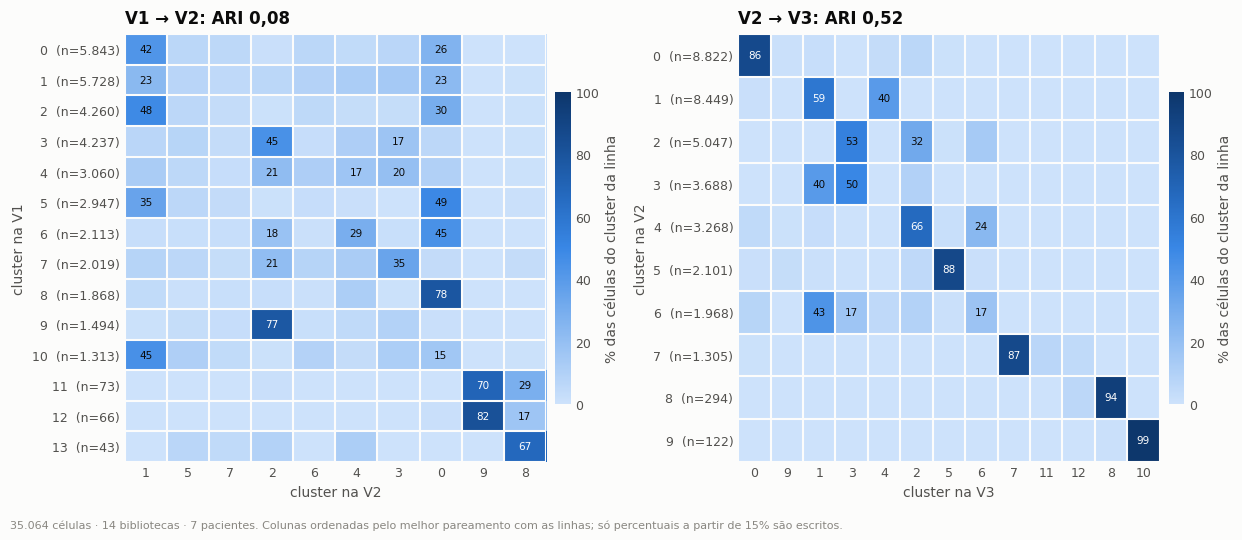

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
dados_fig = []
for ax, (a, b) in zip(axes, [("V1", "V2"), ("V2", "V3")]):
    ct = pl.matched_contingency(res[a].obs["leiden"], res[b].obs["leiden"])
    frac = ct.div(ct.sum(axis=1), axis=0) * 100
    frac.index = [f"{i}  (n={F.n(n)})" for i, n in zip(ct.index, ct.sum(axis=1))]
    plotting.heatmap(ax, frac, vmin=0, vmax=100, fmt=".0f", annotate_above=15,
                     cbar_label="% das células do cluster da linha", xrotation=0)
    ax.set_xlabel(f"cluster na {b}")
    ax.set_ylabel(f"cluster na {a}")
    ax.set_title(f"{a} → {b}: ARI {F.f(acordo.loc[f'{a} × {b}', 'ARI'], 2)}")
    dados_fig.append(ct.stack().rename("celulas").reset_index().set_axis(["cluster_linha", "cluster_coluna", "celulas"], axis=1)
                     .assign(comparacao=f"{a} × {b}"))
plotting.note(fig, f"{F.n(N_CELLS)} células · {plotting.N_DESIGN}. Colunas ordenadas pelo melhor pareamento com as linhas; "
                   "só percentuais a partir de 15% são escritos.")
fig.tight_layout()
plotting.savefig(fig, NB, "concordancia_entre_variantes", description="Para onde vão as células de cada cluster ao mudar de variante",
                 data=pd.concat(dados_fig), data_index=False)
plt.show()

In [13]:
ari12, ari23 = acordo.loc["V1 × V2", "ARI"], acordo.loc["V2 × V3", "ARI"]
ari_seed = acordo.loc["V3 × V3 (outra semente)", "ARI"]
print(f"corrigir a PCA (V1 → V2): ARI {F.f(ari12, 2)}, NMI {F.f(acordo.loc['V1 × V2', 'NMI'], 2)} "
      f"— na corrida antiga, a mesma comparação deu ARI {F.f(antiga05['ARI'], 2)}")
print(f"trocar o universo de genes (V2 → V3): ARI {F.f(ari23, 2)}, NMI {F.f(acordo.loc['V2 × V3', 'NMI'], 2)}")
print(f"referência, mesma análise com outra semente: ARI {F.f(ari_seed, 2)}")

corrigir a PCA (V1 → V2): ARI 0,08, NMI 0,16 — na corrida antiga, a mesma comparação deu ARI 0,09
trocar o universo de genes (V2 → V3): ARI 0,52, NMI 0,60
referência, mesma análise com outra semente: ARI 0,58


**Leitura.** Corrigir a PCA troca a partição quase inteira: ARI 0,08 entre V1
e V2, o mesmo valor que a auditoria anterior encontrou na corrida antiga
(0,09). Os clusters do processamento original são produto do espaço em que
foram calculados, e isso não depende da profundidade de sequenciamento.

A troca do universo de genes (V2 → V3) mexe pouco na estrutura: a maior parte
dos vizinhos de cada célula é a mesma nos dois espaços (coluna "vizinhos em
comum"), e o ARI entre os dois agrupamentos (0,52) é da ordem do ARI entre
duas sementes da mesma análise (0,58). Os clusters bem separados — os
pequenos, na figura — passam de uma variante para a outra quase inteiros; o
que muda é onde o Leiden corta a massa central de células.

A própria referência é um aviso: com outra semente, a V3 dá ARI 0,58 contra
si mesma. Na resolução 0,5 parte das fronteiras entre clusters é arbitrária;
A05 mede isso cluster a cluster.

In [14]:
log.add("MAJOR" if ari12 < 0.5 else "MINOR", "clusters do processamento original (V1)",
        "os clusters da V1 não se mantêm quando a PCA é corrigida",
        evidence=f"ARI V1 × V2 = {F.f(ari12, 2)} (NMI {F.f(acordo.loc['V1 × V2', 'NMI'], 2)}); "
                 f"referência entre sementes = {F.f(ari_seed, 2)}; na corrida antiga a mesma comparação deu "
                 f"ARI {F.f(antiga05['ARI'], 2)}",
        impact="qualquer anotação feita sobre os clusters da V1 herdaria uma partição que depende do defeito da PCA",
        recommendation="não anotar a V1; ela fica no objeto apenas como registro do processamento original")
log.add("INFO" if ari23 >= 0.5 else "MINOR", "universo de genes (V2 × V3)",
        "efeito de trocar a interseção pela união no agrupamento",
        evidence=f"ARI V2 × V3 = {F.f(ari23, 2)} (NMI {F.f(acordo.loc['V2 × V3', 'NMI'], 2)}); referência entre "
                 f"sementes = {F.f(ari_seed, 2)}; {F.n(len(hv_set['inner'] & hv_set['union']))} de {F.n(config.N_HVG)} "
                 f"genes variáveis em comum",
        impact="mede o quanto do agrupamento depende da regra de junção; a estrutura por cluster é avaliada em A05",
        recommendation="seguir com a V3, que mantém as citocinas no objeto")

## 6. Sensibilidade: genes técnicos entre os genes variáveis

A02 mostrou que entram entre os 2.000 genes variáveis alguns genes cuja
variação não é programa celular: segmentos V do TCR (variam por clone),
imunoglobulinas (vêm de células B e do RNA ambiente), genes de sexo e os
sustentados por reads intrônicos isolados (C03). A pergunta aqui é prática:
tirá-los da seleção muda o agrupamento? Roda-se a V3 de novo, proibindo esses
genes e completando os 2.000 com os próximos da mesma ordenação.

In [15]:
iso = pd.read_csv(config.TABLES / "C03_rarefacao_citocinas" / "genes_sustentados_por_reads_isolados.csv", index_col=0)
mapa = pl.symbol_map()
extra = {"reads isolados (C03)": set(mapa.reindex(iso.index).dropna()),
         "sexo (XIST, Y)": {"XIST"} | set(config.Y_GENES)}
classe = pl.classify_genes(union.var_names, extra)
TECNICAS = ["TCR (V)", "imunoglobulina", "reads isolados (C03)", "sexo (XIST, Y)"]
proibidos = set(classe.index[classe.isin(TECNICAS)])
hvg_x = pl.pick_hvg(hvg["union"], config.N_HVG, proibidos)
hv_x = set(hvg_x.index[hvg_x["highly_variable"]])
saem = sorted(hv_set["union"] - hv_x)
assert set(saem) == hv_set["union"] & proibidos and len(hv_x) == config.N_HVG
por_classe = classe[saem].value_counts().reindex(TECNICAS, fill_value=0)

t0 = time.time()
res_x = pl.run_variant(union, "V3", hvg_x)
c_x = pl.clustering_agreement(res["V3"].obs["leiden"], res_x.obs["leiden"])
mantidas = pl.matched_fraction(res["V3"].obs["leiden"], res_x.obs["leiden"])
viz_x = float(np.median(pl.knn_overlap(res["V3"].obsp["distances"], res_x.obsp["distances"])))
viz_23 = float(acordo.loc["V2 × V3", "vizinhos em comum (mediana)"])
sens = pd.DataFrame({
    "genes variáveis trocados": [len(saem)],
    **{f"  {c}": [int(n)] for c, n in por_classe.items()},
    "clusters (V3 → sem genes técnicos)": [f"{res['V3'].obs['leiden'].nunique()} → {res_x.obs['leiden'].nunique()}"],
    "ARI": [c_x["ARI"]], "NMI": [c_x["NMI"]],
    "células que ficam no cluster pareado": [mantidas],
    "vizinhos em comum com a V3 (mediana)": [viz_x],
    "referência: vizinhos em comum V2 × V3": [viz_23],
    "ARI de referência entre sementes": [ari_seed],
}, index=["V3 × V3 sem genes técnicos"]).T
io.save_table(sens, NB, "sensibilidade_genes_tecnicos",
              description="Efeito de excluir TCR-V, IG, genes de sexo e de reads isolados da seleção de genes variáveis")
io.save_table(pd.DataFrame({"gene": saem, "classe": classe[saem].to_numpy()}), NB, "genes_tecnicos_entre_hvg", index=False,
              description="Genes técnicos que entram entre os 2000 genes variáveis da V3")
print(f"{len(saem)} genes trocados; ARI {F.f(c_x['ARI'], 2)}, NMI {F.f(c_x['NMI'], 2)}; "
      f"{F.pct(mantidas)} das células ficam no cluster pareado; vizinhos em comum com a V3: {F.pct(viz_x, 0)} "
      f"(V2 × V3: {F.pct(viz_23, 0)}) ({time.time() - t0:.0f} s)")
sens

  V3: 35,064 células × 31,756 genes no universo; PCA sobre lognorm escalonada; variância em 50 PCs 0.180; 13 clusters; Harmony: Converged after 3 iterations
118 genes trocados; ARI 0,40, NMI 0,59; 56,4% das células ficam no cluster pareado; vizinhos em comum com a V3: 53% (V2 × V3: 40%) (75 s)


,V3 × V3 sem genes técnicos
genes variáveis trocados,118
TCR (V),10
imunoglobulina,22
reads isolados (C03),83
"sexo (XIST, Y)",3
clusters (V3 → sem genes técnicos),13 → 13
ARI,0.395346
NMI,0.586156
células que ficam no cluster pareado,0.564454
vizinhos em comum com a V3 (mediana),0.533333


In [16]:
estavel = viz_x >= viz_23
log.add("INFO" if estavel else "MINOR", "seleção de genes variáveis (V3)",
        "genes técnicos entre os 2.000 genes variáveis: efeito no agrupamento",
        evidence=f"{len(saem)} genes ({', '.join(f'{c} {n}' for c, n in por_classe.items())}); sem eles, ARI "
                 f"{F.f(c_x['ARI'], 2)} contra a V3 (referência entre sementes {F.f(ari_seed, 2)}), "
                 f"{res['V3'].obs['leiden'].nunique()} → {res_x.obs['leiden'].nunique()} clusters, "
                 f"{F.pct(mantidas)} das células no cluster pareado; vizinhos em comum com a V3 {F.pct(viz_x, 0)} "
                 f"(entre V2 e V3: {F.pct(viz_23, 0)})",
        impact=("o agrupamento praticamente não depende desses genes" if estavel else
                "parte do agrupamento da V3 depende de genes cuja variação não é programa celular"),
        recommendation=("exclusão opcional; pode ficar para a etapa de anotação" if estavel else
                        "excluir esses genes da seleção antes de anotar e reavaliar os clusters afetados"))
del res_x

**Leitura.** Tirar os 118 genes técnicos (10 segmentos V de TCR, 22 de
imunoglobulina, 83 sustentados por reads isolados e 3 de sexo) mantém 13
clusters e metade dos vizinhos de cada célula (mediana de 53% em comum com a
V3, mais que os 40% em comum entre V2 e V3). O ARI cai para 0,40, abaixo da
referência entre sementes (0,58): soma-se o efeito da troca de genes à
instabilidade das fronteiras na massa central de células, que já existe sem
ela. A estrutura não depende desses genes; tirá-los da seleção é um
refinamento barato e coerente para a etapa de anotação, não uma correção
obrigatória desta etapa.

## 7. Sensibilidade: corrigir por biblioteca ou por paciente?

O original passa a biblioteca ao Harmony. Neste desenho cada paciente tem
duas bibliotecas — estimulada e não estimulada —, cada uma num canal. Corrigir
por biblioteca trata a diferença entre as duas como lote, e isso inclui o
efeito do estímulo: os dois estão confundidos e nenhum método os separa.
A alternativa é corrigir por paciente, que preserva o que distingue as duas
bibliotecas (estímulo **e** canal).

A medida: para cada célula, entre os vizinhos do mesmo paciente, que fração é
da mesma biblioteca, comparada com o esperado se as duas estivessem
misturadas. O índice vai de 0 (misturadas) a 1 (separadas).

In [17]:
t0 = time.time()
res_p = pl.run_variant(union, "V3", hvg["union"], harmony_key="patient")
lib_arr = union.obs["library_id"].astype(str).to_numpy()
pat_arr = union.obs["patient"].astype(str).to_numpy()
grafos = {"antes do Harmony (PCA)": pl.neighbors_before_harmony(res["V3"]),
          "Harmony por biblioteca (V3, original)": res["V3"].obsp["connectivities"],
          "Harmony por paciente": res_p.obsp["connectivities"]}
sep, linhas = {}, []
for nome, G in grafos.items():
    s_ = pl.within_patient_separation(G, lib_arr, pat_arr).reindex(LIBS)
    sep[nome] = s_["separacao"]
    kp = pl.knn_library_mixing(G, pat_arr)
    linhas.append({"grafo": nome, "separação NS × ML (mediana das bibliotecas)": float(s_["separacao"].median()),
                   "separação: mínimo": float(s_["separacao"].min()), "separação: máximo": float(s_["separacao"].max()),
                   "iLISI de pacientes (mediana)": float(kp["ilisi"].median())})
integ_sens = pd.DataFrame(linhas).set_index("grafo")
integ_sens["iLISI de pacientes esperado"] = pl.expected_ilisi(pat_arr)
c_p = pl.clustering_agreement(res["V3"].obs["leiden"], res_p.obs["leiden"])
integ_sens.loc["Harmony por paciente", "clusters"] = res_p.obs["leiden"].nunique()
integ_sens.loc["Harmony por biblioteca (V3, original)", "clusters"] = res["V3"].obs["leiden"].nunique()
integ_sens.loc["Harmony por paciente", "ARI contra a V3"] = c_p["ARI"]
integ_sens.loc["Harmony por paciente", "células no cluster pareado com a V3"] = pl.matched_fraction(
    res["V3"].obs["leiden"], res_p.obs["leiden"])
integ_sens.loc["Harmony por paciente", "vizinhos em comum com a V3 (mediana)"] = float(
    np.median(pl.knn_overlap(res["V3"].obsp["distances"], res_p.obsp["distances"])))
io.save_table(integ_sens, NB, "sensibilidade_integracao_por_paciente",
              description="Harmony por biblioteca × por paciente: separação entre as duas bibliotecas do paciente e mistura de pacientes")
io.save_table(pd.DataFrame(sep), NB, "separacao_estimulo_por_biblioteca",
              description="Separação entre as duas bibliotecas do mesmo paciente, por biblioteca e por grafo")
print(f"Harmony por paciente: {res_p.uns['reseq_variant']['harmony']}; {res_p.obs['leiden'].nunique()} clusters; "
      f"ARI contra a V3 {F.f(c_p['ARI'], 2)} ({time.time() - t0:.0f} s)")
integ_sens.round(3)

  V3: 35,064 células × 31,756 genes no universo; PCA sobre lognorm escalonada; variância em 50 PCs 0.180; 13 clusters; Harmony: Converged after 3 iterations


Harmony por paciente: Converged after 3 iterations; 13 clusters; ARI contra a V3 0,50 (55 s)


,separação NS × ML (mediana das bibliotecas),separação: mínimo,separação: máximo,iLISI de pacientes (mediana),iLISI de pacientes esperado,clusters,ARI contra a V3,células no cluster pareado com a V3,vizinhos em comum com a V3 (mediana)
grafo,,,,,,,,,
antes do Harmony (PCA),0.607,0.352,0.938,1.256,4.113,NaN,NaN,NaN,NaN
"Harmony por biblioteca (V3, original)",0.220,-0.161,0.663,2.843,4.113,13.0,NaN,NaN,NaN
Harmony por paciente,0.628,0.312,0.930,2.597,4.113,13.0,0.502,0.678,0.6


In [18]:
s_antes, s_lib, s_pat = (integ_sens.loc[k, "separação NS × ML (mediana das bibliotecas)"] for k in grafos)
log.add("MAJOR", "processing.ipynb célula 057 — Harmony com vars_use='library_id'",
        "a correção por biblioteca reduz também a diferença entre estimulado e não estimulado do mesmo paciente",
        evidence=f"separação entre as duas bibliotecas do paciente (0 = misturadas, 1 = separadas): {F.f(s_antes, 2)} antes do "
                 f"Harmony, {F.f(s_lib, 2)} com Harmony por biblioteca, {F.f(s_pat, 2)} com Harmony por paciente; "
                 f"ARI entre os dois agrupamentos {F.f(c_p['ARI'], 2)}",
        impact="estímulo e canal estão confundidos (uma biblioteca = um canal = uma condição); no espaço integrado por "
               "biblioteca, a ausência de um cluster de células estimuladas não prova ausência de resposta",
        recommendation="testar o efeito do estímulo nas contagens (pseudobulk pareado por paciente), que não depende da "
                       "integração; se a composição por cluster for usada, repetir com Harmony por paciente e comparar")
del res_p

**Leitura.** Antes do Harmony as duas bibliotecas de cada paciente estão bem
separadas na vizinhança (índice mediano 0,61). A correção por biblioteca — a
do original — derruba essa separação para 0,22; a correção por paciente a
mantém (0,63) e ainda mistura os pacientes quase tanto quanto (iLISI de
pacientes 2,60 contra 2,84; o esperado sob mistura perfeita é 4,11). Os dois
agrupamentos concordam só em parte (ARI 0,50; 68% das células no cluster
pareado).

Nenhuma das duas escolhas é "a correta": por biblioteca remove o efeito de
canal e leva junto o do estímulo; por paciente preserva os dois, sem como
separá-los. O que os dados permitem afirmar é que a comparação estimulado ×
não estimulado não deve depender do espaço integrado — e que a ausência de
clusters próprios do estímulo na V3 é, em boa parte, efeito da correção.

## 8. Visão geral dos três agrupamentos

Cada painel mostra o UMAP de uma variante, com o número de cada cluster no
seu centro. Os números são rótulos arbitrários de cada execução: o cluster 3
de uma variante não corresponde ao cluster 3 de outra (a correspondência é a
da figura anterior). A leitura por biblioteca e por cluster está em A05.

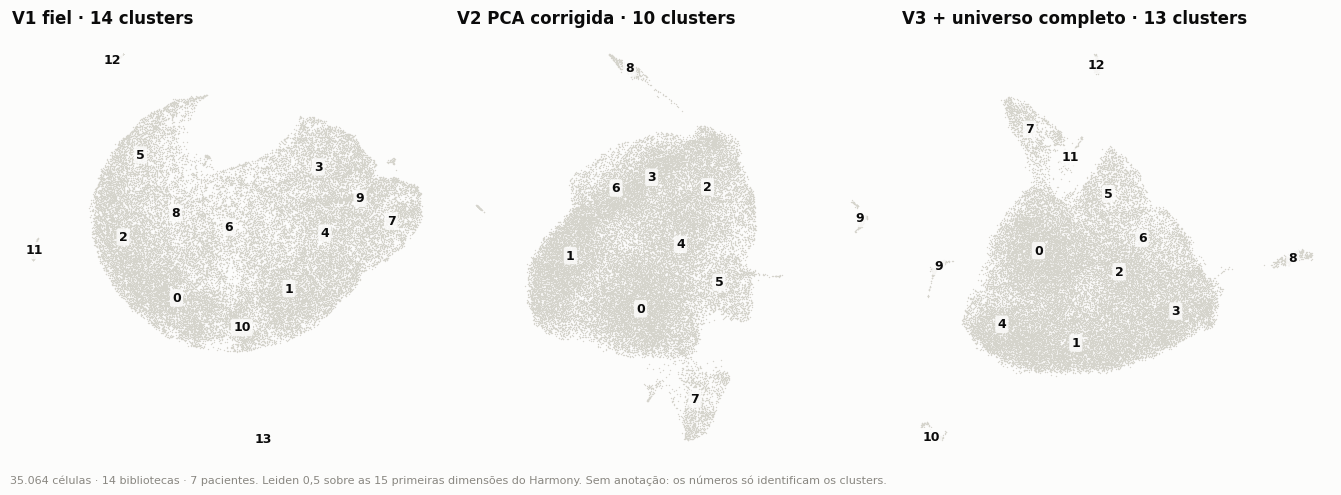

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8))
for ax, v in zip(axes, VARS):
    plotting.umap_labeled(ax, res[v].obsm["X_umap"], res[v].obs["leiden"].astype(str),
                          title=f"{VLAB[v]} · {res[v].obs['leiden'].nunique()} clusters")
plotting.note(fig, f"{F.n(N_CELLS)} células · {plotting.N_DESIGN}. Leiden 0,5 sobre as 15 primeiras dimensões do Harmony. "
                   "Sem anotação: os números só identificam os clusters.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "umap_variantes", description="UMAP e clusters do Leiden em cada variante",
                 data=pd.DataFrame(tam).pipe(lambda d: d.loc[sorted(d.index, key=int)])
                        .rename_axis("cluster").reset_index(), data_index=False)
plt.show()

## 9. Objeto integrado

Um único objeto guarda as três variantes sobre as mesmas células e o universo
completo de genes: `X` é a lognorm, `layers["counts"]` as contagens. Cada
variante entra com sufixo (`leiden_V1`, `X_umap_V2`, `connectivities_V3`…) e
as chaves sem sufixo apontam para a V3. Antes de gravar, as contagens são
conferidas entrada por entrada contra as matrizes do Cell Ranger.

In [20]:
integ = pl.assemble(union, res, default="V3")
integ.var["na_intersecao"] = integ.var_names.isin(inner.var_names)
integ.var["classe_gene"] = classe.reindex(integ.var_names).to_numpy()
integ.var["citocina"] = integ.var_names.isin(config.CYTOKINES)

confere = pl.counts_match_cellranger(integ)
io.save_table(confere, NB, "contagens_conferidas", description="Contagens do objeto integrado × matrizes filtradas do Cell Ranger")
assert (confere["entradas_diferentes"] == 0).all() and (confere["umis_cellranger"] == confere["umis_objeto"]).all()
print(f"contagens conferidas contra o Cell Ranger: {F.n(confere['celulas'].sum())} células, "
      f"{F.n(confere['umis_objeto'].sum())} UMIs, 0 entradas diferentes")

caminho = io.save_data(integ, NB, "reseq_integrado",
                       description="Objeto integrado do ressequenciamento: universo completo, contagens, lognorm e as "
                                   "variantes V1, V2 e V3 (PCA, Harmony, UMAP, grafo, Leiden); padrão = V3")
print(f"gravado: {caminho}  ({caminho.stat().st_size / 1e6:.0f} MB)")
print(integ)

contagens conferidas contra o Cell Ranger: 35.064 células, 365.654.123 UMIs, 0 entradas diferentes


gravado: /mnt/SATA/singleCellTaru/dataReseq/A04_processamento_integracao/reseq_integrado.h5ad  (576 MB)
AnnData object with n_obs × n_vars = 35064 × 31756
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'mt_outlier', 'doublet_score', 'predicted_doublet', 'library_id', 'barcode', 'cell_key', 'controles', 'classificacao', 'estimulo', 'patient', 'classification', 'stimulation', 'total_counts_rps', 'log1p_total_counts_rps', 'pct_counts_rps', 'total_counts_rpl', 'log1p_total_counts_rpl', 'pct_counts_rpl', 'leiden_V1', 'leiden_V2', 'leiden_V3', 'leiden'
    var: 'gene_ids', 'gene_symbol', 'mt', 'rps', 'rpl', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable_V1', 'highly_variable_

## Problemas encontrados

In [21]:
if not all(str(x).startswith("Converged") for x in variantes["Harmony"]):
    log.add("MINOR", "Harmony", "o Harmony parou no limite de iterações em pelo menos uma variante",
            evidence="; ".join(f"{i}: {x}" for i, x in variantes["Harmony"].items()),
            impact="a correção pode estar incompleta; a mistura de bibliotecas é medida em A05",
            recommendation="aumentar max_iter_harmony se a mistura medida em A05 for insuficiente")
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    1
MAJOR       2
MINOR       0
INFO        3


severity,location,problem,evidence,impact,recommendation
CRITICAL,processing.ipynb célula 054 → variante V1,"aplicado aos dados novos, o processamento original volta a calcular a PCA sobre contagens cruas","V1: 98,1% da variância em 50 componentes (V2: 16,9%); 91,7% da variância da matriz em 10 genes (MALAT1, IGKC, IGLC2, FTH1, IGHA1); |ρ| das 3 primeiras dimensões do Harmony com os UMIs 0,74, 0,70, 0,43 (corrida antiga: 0,70, 0,66, 0,50)","o grafo, o UMAP e os clusters da V1 são construídos num espaço dominado pela escala das contagens; o ressequenciamento não altera isso, porque a causa está no código",usar a PCA sobre a lognorm escalonada dos genes variáveis (V2/V3)
MAJOR,clusters do processamento original (V1),os clusters da V1 não se mantêm quando a PCA é corrigida,"ARI V1 × V2 = 0,08 (NMI 0,16); referência entre sementes = 0,58; na corrida antiga a mesma comparação deu ARI 0,09",qualquer anotação feita sobre os clusters da V1 herdaria uma partição que depende do defeito da PCA,não anotar a V1; ela fica no objeto apenas como registro do processamento original
MAJOR,processing.ipynb célula 057 — Harmony com vars_use='library_id',a correção por biblioteca reduz também a diferença entre estimulado e não estimulado do mesmo paciente,"separação entre as duas bibliotecas do paciente (0 = misturadas, 1 = separadas): 0,61 antes do Harmony, 0,22 com Harmony por biblioteca, 0,63 com Harmony por paciente; ARI entre os dois agrupamentos 0,50","estímulo e canal estão confundidos (uma biblioteca = um canal = uma condição); no espaço integrado por biblioteca, a ausência de um cluster de células estimuladas não prova ausência de resposta","testar o efeito do estímulo nas contagens (pseudobulk pareado por paciente), que não depende da integração; se a composição por cluster for usada, repetir com Harmony por paciente e comparar"
INFO,réplica do processing.ipynb (variante V1),[VERIFICAÇÃO] a V1 reproduz o resultado gravado pelo notebook original,"2.000 de 2.000 genes variáveis em comum; menor |r| das 10 primeiras dimensões do Harmony 1,0000; índice de Rand ajustado 1,0000","o comportamento da V1 nos dados novos pode ser atribuído ao processamento original, não à réplica",nenhuma
INFO,universo de genes (V2 × V3),efeito de trocar a interseção pela união no agrupamento,"ARI V2 × V3 = 0,52 (NMI 0,60); referência entre sementes = 0,58; 1.478 de 2.000 genes variáveis em comum",mede o quanto do agrupamento depende da regra de junção; a estrutura por cluster é avaliada em A05,"seguir com a V3, que mantém as citocinas no objeto"
INFO,seleção de genes variáveis (V3),genes técnicos entre os 2.000 genes variáveis: efeito no agrupamento,"118 genes (TCR (V) 10, imunoglobulina 22, reads isolados (C03) 83, sexo (XIST, Y) 3); sem eles, ARI 0,40 contra a V3 (referência entre sementes 0,58), 13 → 13 clusters, 56,4% das células no cluster pareado; vizinhos em comum com a V3 53% (entre V2 e V3: 40%)",o agrupamento praticamente não depende desses genes,exclusão opcional; pode ficar para a etapa de anotação


## Conclusão

* A réplica do processamento original está conferida contra o resultado
  gravado, de modo que a V1 representa o que o notebook original faria com os
  dados novos.
* O defeito da PCA sobre contagens cruas está no código e reaparece
  independentemente da profundidade de sequenciamento. Os números das seções
  4 e 5 medem o tamanho do efeito nos dados novos.
* A V3 é a linha de base proposta: corrige a PCA e mantém no objeto os genes
  que a interseção descartava, entre eles as citocinas.
* O objeto gravado traz as três variantes lado a lado, para que A05 avalie
  cada agrupamento com as mesmas medidas.

In [22]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

23 artefatos gravados por este notebook:
                                 name    kind
                fidelidade_da_replica   table
                     antiga_variantes parquet
          variantes_na_corrida_antiga   table
               citocinas_por_universo   table
                   universos_de_genes   table
                            variantes   table
                     pca_concentracao   table
                pca_cargas_principais   table
            profundidade_por_dimensao   table
                 fig_pca_por_variante  figure
                 fig_pca_por_variante   table
         concordancia_entre_variantes   table
     fig_concordancia_entre_variantes  figure
     fig_concordancia_entre_variantes   table
         sensibilidade_genes_tecnicos   table
             genes_tecnicos_entre_hvg   table
sensibilidade_integracao_por_paciente   table
    separacao_estimulo_por_biblioteca   table
                   fig_umap_variantes  figure
                   fig_umap_variantes  